# AniWise — Crop Recommendation: Multi-Class Classification (revised)
Compares **Decision Tree**, **Logistic Regression**, and **Random Forest** on seven soil/climate features to predict one of 22 crops.

**Experimental design (follows the course requirements):**
1. 80/20 stratified split. The **test set is not touched** until the final model has been selected.
2. All three algorithms use the same split, the same 5-fold stratified CV folds, and the same primary metric (macro-F1).
3. Model selection uses **cross-validation on the training set only**.
4. The selected model is evaluated **once** on the held-out test set.

Run the cells top to bottom. Locally, the CSV is read from `data/original/Crop_recommendation.csv` (or the working folder). In Google Colab, you will be asked to upload it.

In [1]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:   # pin the version the deployed model was trained with
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "scikit-learn==1.9.0", "pandas", "matplotlib", "seaborn", "numpy"])

In [2]:
import os, io, json, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, cross_validate, cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, precision_recall_fscore_support
)

RANDOM_STATE = 42
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"
FIG_DIR, RES_DIR = "figures", "results"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 110,
                     "savefig.dpi": 300, "savefig.bbox": "tight"})
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"))

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.0


## 1. Load the dataset

In [3]:
CANDIDATES = ["data/original/Crop_recommendation.csv", "../data/original/Crop_recommendation.csv",
              "data/Crop_recommendation.csv", "Crop_recommendation.csv"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()          # choose Crop_recommendation.csv
    DATA_PATH = list(uploaded.keys())[0]
if DATA_PATH is None:
    raise FileNotFoundError("Place Crop_recommendation.csv in data/original/ (or the working folder).")
print("Loaded:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

Loaded: Crop_recommendation.csv
(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 2. Exploratory Data Analysis

### 2.1 Dimensions, data types, summary statistics, and data-quality checks

In [4]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)

summary = df[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(2)
summary.columns = ["Mean", "Std", "Min", "Median", "Max"]
summary.to_csv(os.path.join(RES_DIR, "summary_statistics.csv"))
display(summary)

print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# Impossible-value checks (physical plausibility)
rules = {
    "N":           lambda s: s < 0,
    "P":           lambda s: s < 0,
    "K":           lambda s: s < 0,
    "temperature": lambda s: (s < -10) | (s > 60),
    "humidity":    lambda s: (s < 0) | (s > 100),
    "ph":          lambda s: (s < 0) | (s > 14),
    "rainfall":    lambda s: s < 0,
}
impossible = {f: int(rule(df[f]).sum()) for f, rule in rules.items()}
print("\nImpossible values per feature:", impossible)

# Label consistency (spelling/whitespace/case variants)
print("Distinct labels:", df[TARGET].nunique(),
      "| labels with whitespace/case variants:", int((df[TARGET] != df[TARGET].str.strip().str.lower()).sum()))

Shape: (2200, 8)

Data types:
 N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object


,Mean,Std,Min,Median,Max
N,50.55,36.92,0.00,37.00,140.00
P,53.36,32.99,5.00,51.00,145.00
K,48.15,50.65,5.00,32.00,205.00
temperature,25.62,5.06,8.83,25.60,43.68
humidity,71.48,22.26,14.26,80.47,99.98
ph,6.47,0.77,3.50,6.43,9.94
rainfall,103.46,54.96,20.21,94.87,298.56



Missing values per column:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0

Impossible values per feature: {'N': 0, 'P': 0, 'K': 0, 'temperature': 0, 'humidity': 0, 'ph': 0, 'rainfall': 0}
Distinct labels: 22 | labels with whitespace/case variants: 0


### 2.2 Class distribution

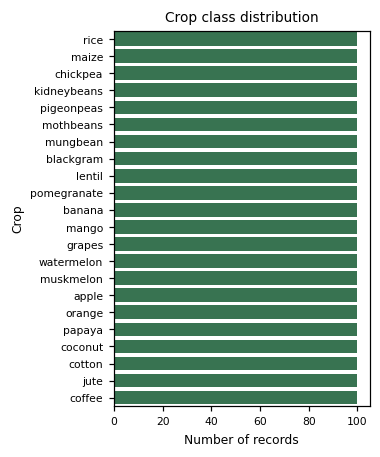

min    100.0
max    100.0
Name: count, dtype: float64


In [5]:
order = df[TARGET].value_counts().index
fig, ax = plt.subplots(figsize=(3.5, 4.2))
sns.countplot(data=df, y=TARGET, order=order, color="#2e7d4f", ax=ax)
ax.set_xlabel("Number of records"); ax.set_ylabel("Crop")
ax.set_title("Crop class distribution")
plt.tight_layout(); savefig("fig01_class_distribution"); plt.show()
print(df[TARGET].value_counts().describe()[["min", "max"]])

### 2.3 Univariate distributions

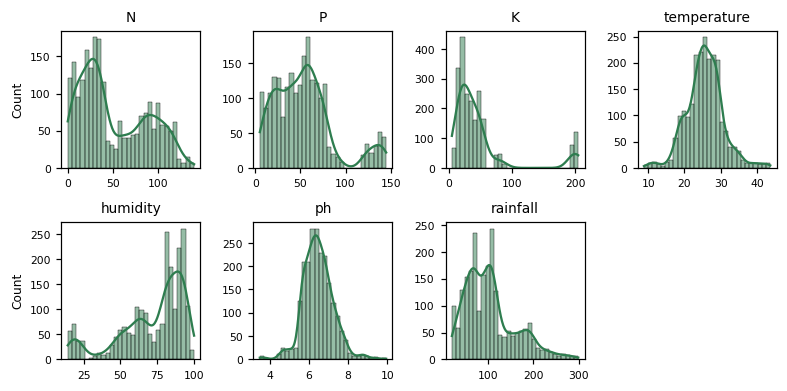

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.6)); axes = axes.flatten()
for i, col in enumerate(FEATURES):
    sns.histplot(df[col], kde=True, ax=axes[i], color="#2e7d4f", bins=30)
    axes[i].set_title(col); axes[i].set_xlabel(""); axes[i].set_ylabel("Count" if i % 4 == 0 else "")
axes[-1].axis("off")
plt.tight_layout(); savefig("fig02_feature_distributions"); plt.show()

### 2.4 Outlier investigation (statistical outliers vs. data errors)

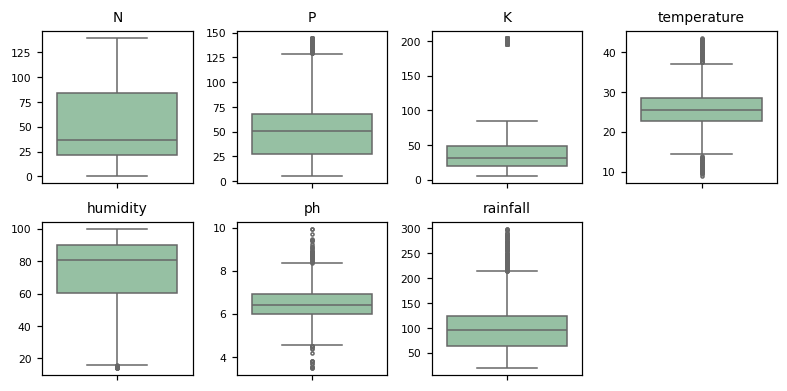

,Feature,IQR outliers,% of records,Crops involved,Top crops (count),% in top-2 crops
0,N,0,0.00,0,,0.0
1,P,138,6.27,2,"apple (70), grapes (68)",100.0
2,K,200,9.09,2,"grapes (100), apple (100)",100.0
3,temperature,86,3.91,3,"papaya (35), grapes (34), orange (17)",80.2
4,humidity,30,1.36,1,chickpea (30),100.0
5,ph,57,2.59,3,"mothbeans (42), chickpea (13), mango (2)",96.5
6,rainfall,100,4.55,3,"rice (68), papaya (17), coconut (15)",85.0


In [7]:
fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.6)); axes = axes.flatten()
for i, col in enumerate(FEATURES):
    sns.boxplot(y=df[col], ax=axes[i], color="#8fc7a0", fliersize=2)
    axes[i].set_title(col); axes[i].set_ylabel("")
axes[-1].axis("off")
plt.tight_layout(); savefig("fig03_boxplots"); plt.show()

# Which crops do the IQR outliers belong to?
rows = []
for f in FEATURES:
    q1, q3 = df[f].quantile([.25, .75]); iqr = q3 - q1
    out = df[(df[f] < q1 - 1.5 * iqr) | (df[f] > q3 + 1.5 * iqr)]
    top = out[TARGET].value_counts()
    rows.append({
        "Feature": f, "IQR outliers": len(out),
        "% of records": round(100 * len(out) / len(df), 2),
        "Crops involved": top.size,
        "Top crops (count)": ", ".join(f"{k} ({v})" for k, v in top.head(3).items()),
        "% in top-2 crops": round(100 * top.head(2).sum() / max(len(out), 1), 1),
    })
outlier_table = pd.DataFrame(rows)
outlier_table.to_csv(os.path.join(RES_DIR, "outlier_investigation.csv"), index=False)
display(outlier_table)

### 2.5 Correlation and feature–target relationships

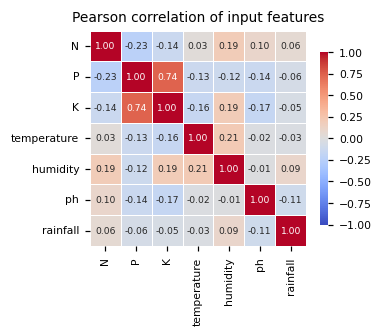

Strongest absolute correlations:
 P            K           0.736
             N           0.231
temperature  humidity    0.205
dtype: float64


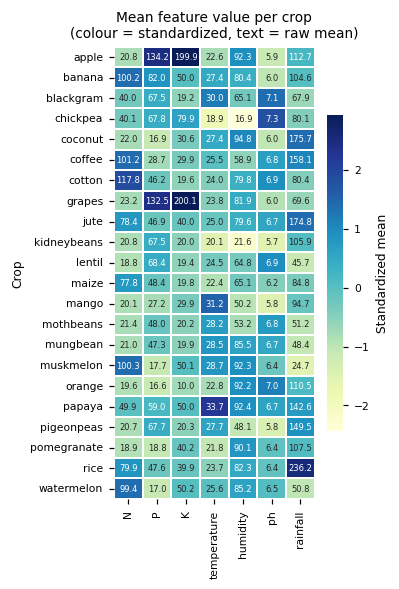

N            highest mean: cotton (117.8) | lowest: lentil (18.8)
P            highest mean: apple (134.2) | lowest: orange (16.6)
K            highest mean: grapes (200.1) | lowest: orange (10.0)
temperature  highest mean: papaya (33.7) | lowest: chickpea (18.9)
humidity     highest mean: coconut (94.8) | lowest: chickpea (16.9)
ph           highest mean: chickpea (7.3) | lowest: kidneybeans (5.7)
rainfall     highest mean: rice (236.2) | lowest: muskmelon (24.7)


In [8]:
fig, ax = plt.subplots(figsize=(3.5, 3.1))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.4, annot_kws={"size": 6}, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation of input features")
plt.tight_layout(); savefig("fig04_correlation_matrix"); plt.show()

pairs = df[FEATURES].corr().abs().where(~np.eye(len(FEATURES), dtype=bool)).stack().sort_values(ascending=False)
print("Strongest absolute correlations:\n", pairs.drop_duplicates().head(3).round(3))

crop_means = df.groupby(TARGET)[FEATURES].mean()
z = (crop_means - crop_means.mean()) / crop_means.std()          # colours: standardized per feature
fig, ax = plt.subplots(figsize=(3.6, 5.4))
sns.heatmap(z, cmap="YlGnBu", annot=crop_means.round(1).astype(str), fmt="", annot_kws={"size": 5.5},
            cbar_kws={"label": "Standardized mean", "shrink": 0.7}, linewidths=0.3, ax=ax)
ax.set_ylabel("Crop"); ax.set_title("Mean feature value per crop\n(colour = standardized, text = raw mean)")
plt.tight_layout(); savefig("fig05_mean_feature_per_crop"); plt.show()

for f in FEATURES:
    print(f"{f:12s} highest mean: {crop_means[f].idxmax()} ({crop_means[f].max():.1f}) | lowest: {crop_means[f].idxmin()} ({crop_means[f].min():.1f})")

### EDA findings summary (each finding informs a decision)
| Finding | Decision / implication |
|---|---|
| 2,200 records, 7 numeric features, 22 classes; **0 missing values, 0 duplicates, 0 impossible values**, no label spelling variants | No imputation, deduplication, or cleaning was needed. |
| All 22 classes have exactly 100 records (perfectly balanced) | Stratified split; no resampling or class weights; accuracy and macro-averaged metrics are both meaningful. |
| IQR outliers occur in P, K, temperature, humidity, pH and rainfall (none in N). They are concentrated in a few crops: all K and P outliers belong to apple and grapes, all humidity outliers to chickpea, 68% of rainfall outliers to rice. | They are legitimate crop-specific extremes, not data errors, so **no outliers were removed**. |
| N, P, K, humidity and rainfall are multimodal, consistent with each crop forming its own cluster | Tree-based models, which handle non-linear and clustered structure, are appropriate to compare with a linear baseline. |
| Only one strong correlation: P–K (r ≈ 0.74); all other pairs are weak | Limited multicollinearity; no feature removal or dimensionality reduction applied. |
| Crop mean profiles differ clearly (e.g., rice has the highest mean rainfall; apple and grapes the highest K; chickpea the lowest humidity) | Classes are distinguishable from these features, supporting classification. |
| Features are on very different scales (pH ≈ 3.5–9.9, rainfall ≈ 20–299) | Scale only the scale-sensitive model (Logistic Regression), inside its pipeline. |

## 3. Stratified train/test split (the test set is set aside here)

In [9]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
class_labels = sorted(y_train.unique())
print(f"Train: {X_train.shape} | Test: {X_test.shape} (test set is NOT used until final evaluation)")
print("Records per class -> train:", y_train.value_counts().unique(), "| test:", y_test.value_counts().unique())

Train: (1760, 7) | Test: (440, 7) (test set is NOT used until final evaluation)
Records per class -> train: [80] | test: [20]


## 4. Pipelines
- **Logistic Regression** uses `StandardScaler` inside its pipeline, so the scaler is fitted only on the training portion of each CV fold (no leakage).
- **Decision Tree** and **Random Forest** use no scaling (axis-aligned splits are scale-invariant).

In [10]:
def build_pipelines(random_state=RANDOM_STATE):
    return {
        "Decision Tree": Pipeline([("classifier", DecisionTreeClassifier(random_state=random_state))]),
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(max_iter=2000, random_state=random_state))]),
        "Random Forest": Pipeline([("classifier", RandomForestClassifier(random_state=random_state))]),
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # same folds for every model
SCORING = {"accuracy": "accuracy", "precision_macro": "precision_macro",
           "recall_macro": "recall_macro", "f1_macro": "f1_macro"}

def cv_summary(name, model, stage):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    row = {"stage": stage, "model": name}
    for k in SCORING:
        v = res[f"test_{k}"]
        row[f"{k}_mean"], row[f"{k}_std"] = v.mean(), v.std()
    return row

## 5. Baseline models (default hyperparameters) — validated with 5-fold CV on the training set only

In [11]:
baseline_rows = [cv_summary(n, p, "baseline") for n, p in build_pipelines().items()]
pd.DataFrame(baseline_rows).round(4)

,stage,model,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std
0,baseline,Decision Tree,0.9852,0.0068,0.9865,0.0061,0.9852,0.0068,0.9852,0.0068
1,baseline,Logistic Regression,0.9682,0.0066,0.9710,0.0059,0.9682,0.0066,0.9678,0.0068
2,baseline,Random Forest,0.9938,0.0061,0.9946,0.0050,0.9938,0.0061,0.9937,0.0061


## 6. Hyperparameter tuning with `GridSearchCV` (5-fold stratified CV, scoring = macro-F1)

In [12]:
def get_param_grids():
    return {
        "Decision Tree": {
            "classifier__criterion": ["gini", "entropy"],
            "classifier__max_depth": [5, 8, 10, 15, None],
            "classifier__min_samples_split": [2, 5, 10],
            "classifier__min_samples_leaf": [1, 2, 4]},
        "Logistic Regression": {
            "classifier__C": [0.01, 0.1, 1, 10, 100],
            "classifier__solver": ["lbfgs"]},
        "Random Forest": {
            "classifier__n_estimators": [100, 200, 300],
            "classifier__max_depth": [8, 12, 16, None],
            "classifier__min_samples_split": [2, 5],
            "classifier__min_samples_leaf": [1, 2],
            "classifier__max_features": ["sqrt", "log2"]},
    }

tuned_models, best_params, search_best = {}, {}, {}
for name, pipe in build_pipelines().items():
    search = GridSearchCV(pipe, get_param_grids()[name], cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    best_params[name] = {k.replace("classifier__", ""): v for k, v in search.best_params_.items()}
    search_best[name] = search.best_score_
    print(f"[{name}] best params: {best_params[name]} | best CV macro-F1: {search.best_score_:.4f}")

[Decision Tree] best params: {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 5} | best CV macro-F1: 0.9858


[Logistic Regression] best params: {'C': 100, 'solver': 'lbfgs'} | best CV macro-F1: 0.9776


[Random Forest] best params: {'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200} | best CV macro-F1: 0.9960


## 7. Validation of the tuned models (5-fold CV on the training set) — same metrics for all three algorithms

In [13]:
tuned_rows = [cv_summary(n, m, "tuned") for n, m in tuned_models.items()]
cv_table = pd.DataFrame(baseline_rows + tuned_rows)
cv_table.to_csv(os.path.join(RES_DIR, "cv_results_all_metrics.csv"), index=False)
display(cv_table.round(4))

with open(os.path.join(RES_DIR, "best_hyperparameters.json"), "w") as f:
    json.dump({k: {a: (None if b is None else b) for a, b in v.items()} for k, v in best_params.items()}, f, indent=2)

,stage,model,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std
0,baseline,Decision Tree,0.9852,0.0068,0.9865,0.0061,0.9852,0.0068,0.9852,0.0068
1,baseline,Logistic Regression,0.9682,0.0066,0.9710,0.0059,0.9682,0.0066,0.9678,0.0068
2,baseline,Random Forest,0.9938,0.0061,0.9946,0.0050,0.9938,0.0061,0.9937,0.0061
3,tuned,Decision Tree,0.9858,0.0067,0.9867,0.0066,0.9858,0.0067,0.9858,0.0067
4,tuned,Logistic Regression,0.9778,0.0058,0.9794,0.0052,0.9778,0.0058,0.9776,0.0058
5,tuned,Random Forest,0.9960,0.0050,0.9965,0.0044,0.9960,0.0050,0.9960,0.0050


### 7.1 Out-of-fold predictions: per-class metrics, confusion matrices, ROC AUC (training data only)

,model,roc_auc_ovr_macro
0,Decision Tree,0.9946
1,Logistic Regression,0.9997
2,Random Forest,1.0000



Decision Tree - weakest classes (out-of-fold F1):


,crop,precision,recall,f1
8,jute,0.926,0.938,0.932
13,mothbeans,0.962,0.938,0.949
20,rice,0.950,0.950,0.950



Logistic Regression - weakest classes (out-of-fold F1):


,crop,precision,recall,f1
30,jute,0.841,0.862,0.852
42,rice,0.883,0.850,0.866
35,mothbeans,0.987,0.950,0.968



Random Forest - weakest classes (out-of-fold F1):


,crop,precision,recall,f1
64,rice,1.000,0.950,0.974
52,jute,0.952,1.000,0.976
57,mothbeans,1.000,0.975,0.987


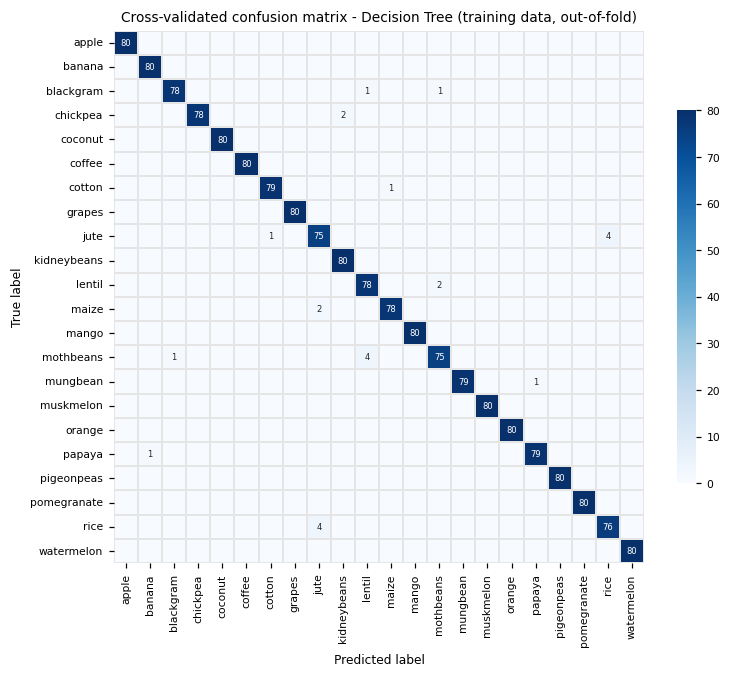

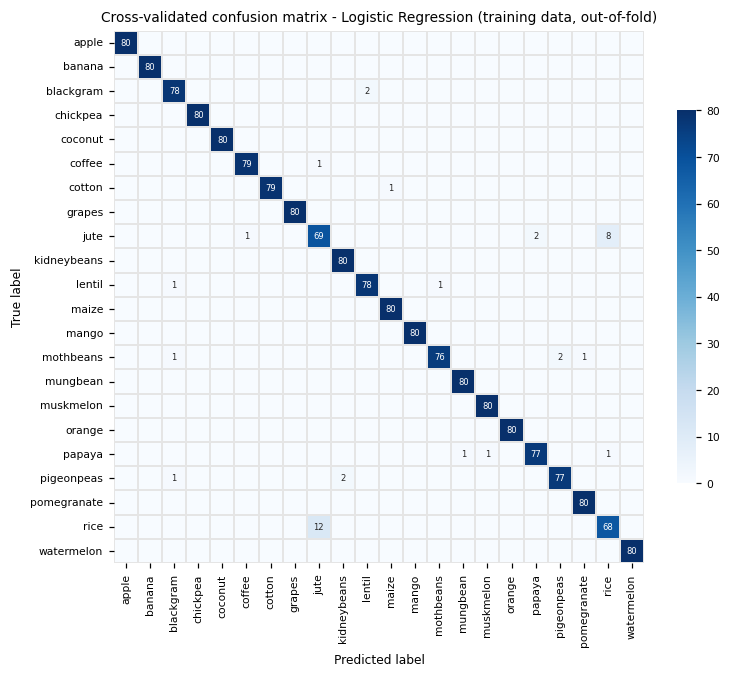

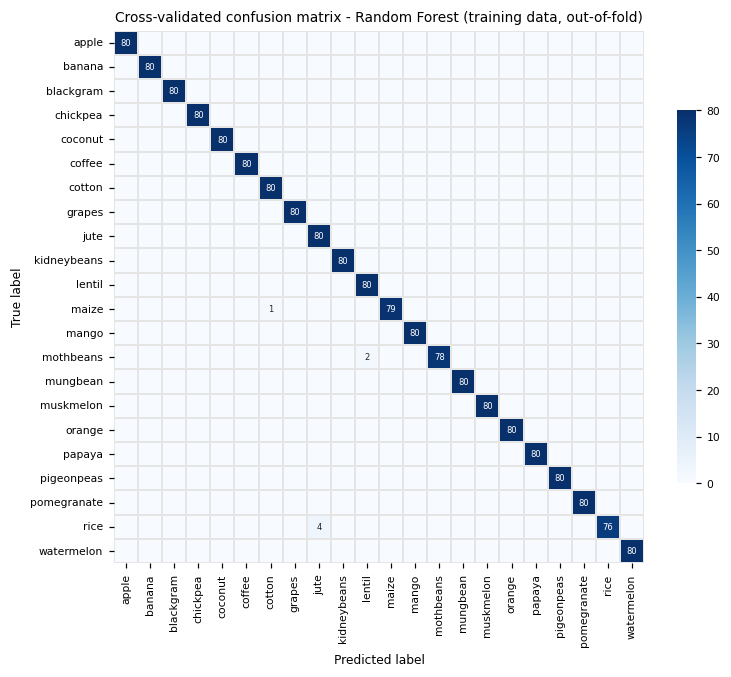

In [14]:
oof_pred, oof_proba, auc_rows = {}, {}, []
for name, model in tuned_models.items():
    oof_pred[name] = cross_val_predict(model, X_train, y_train, cv=cv, n_jobs=-1)
    oof_proba[name] = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)
    auc = roc_auc_score(y_train, oof_proba[name], multi_class="ovr", average="macro", labels=class_labels)
    auc_rows.append({"model": name, "roc_auc_ovr_macro": auc})
auc_table = pd.DataFrame(auc_rows)
auc_table.to_csv(os.path.join(RES_DIR, "roc_auc_oof.csv"), index=False)
display(auc_table.round(4))

per_class_rows = []
for name in tuned_models:
    p, r, f1, s = precision_recall_fscore_support(y_train, oof_pred[name], labels=class_labels, zero_division=0)
    for c, pp, rr, ff, ss in zip(class_labels, p, r, f1, s):
        per_class_rows.append({"model": name, "crop": c, "precision": pp, "recall": rr, "f1": ff, "support": ss})
per_class = pd.DataFrame(per_class_rows)
per_class.to_csv(os.path.join(RES_DIR, "per_class_validation_metrics.csv"), index=False)
for name in tuned_models:
    weakest = per_class[per_class.model == name].sort_values("f1").head(3)[["crop", "precision", "recall", "f1"]]
    print(f"\n{name} - weakest classes (out-of-fold F1):"); display(weakest.round(3))

def plot_cm(cm, labels, title, fname, size=(7.2, 6.2)):
    annot = np.where(cm == 0, "", cm.astype(str))
    fig, ax = plt.subplots(figsize=size)
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", xticklabels=labels, yticklabels=labels,
                annot_kws={"size": 5.5}, cbar_kws={"shrink": 0.7}, linewidths=0.2, linecolor="#e5e5e5", ax=ax)
    ax.set_title(title); ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
    plt.xticks(rotation=90); plt.yticks(rotation=0)
    plt.tight_layout(); savefig(fname); plt.show()

for name in tuned_models:
    cm = confusion_matrix(y_train, oof_pred[name], labels=class_labels)
    plot_cm(cm, class_labels, f"Cross-validated confusion matrix - {name} (training data, out-of-fold)",
            "figS_cv_confusion_" + name.lower().replace(" ", "_"))

### 7.2 Practical suitability: training time, prediction latency, model size, interpretability

In [15]:
def median_fit_time(model, repeats=3):
    ts = []
    for _ in range(repeats):
        m = clone(model); t = time.perf_counter(); m.fit(X_train, y_train); ts.append(time.perf_counter() - t)
    return float(np.median(ts))

def median_latency_ms(model, n=100):
    row = X_train.iloc[[0]]                     # an input row from the TRAINING set (no test data used)
    ts = []
    for _ in range(n):
        t = time.perf_counter(); model.predict(row); ts.append((time.perf_counter() - t) * 1000)
    return float(np.median(ts))

def model_size_kb(model):
    buf = io.BytesIO(); joblib.dump(model, buf); return buf.getbuffer().nbytes / 1024

interp = {"Decision Tree": "High (readable rules)",
          "Logistic Regression": "High (one coefficient per feature and class)",
          "Random Forest": "Moderate (feature importances; ensemble of trees)"}
eff_rows = []
for name, model in tuned_models.items():
    eff_rows.append({"model": name,
                     "train_time_s": median_fit_time(model),
                     "single_prediction_ms": median_latency_ms(model),
                     "model_size_KB": model_size_kb(model),
                     "interpretability": interp[name]})
eff_table = pd.DataFrame(eff_rows)
eff_table.to_csv(os.path.join(RES_DIR, "practical_suitability.csv"), index=False)
display(eff_table.round(4))

,model,train_time_s,single_prediction_ms,model_size_KB,interpretability
0,Decision Tree,0.0129,0.9917,18.1973,High (readable rules)
1,Logistic Regression,0.1085,1.3410,3.3994,High (one coefficient per feature and class)
2,Random Forest,0.6900,16.0143,6460.2988,Moderate (feature importances; ensemble of trees)


## 8. Model selection — by cross-validation macro-F1 only (the test set has not been used)
The primary metric is **macro-F1**. The model with the highest mean CV macro-F1 is selected (ties are broken by the lower standard deviation).

In [16]:
ranking = (cv_table[cv_table.stage == "tuned"]
           .sort_values(["f1_macro_mean", "f1_macro_std"], ascending=[False, True])
           [["model", "f1_macro_mean", "f1_macro_std", "accuracy_mean"]].reset_index(drop=True))
display(ranking.round(4))
best_model_name = ranking.loc[0, "model"]
best_model = tuned_models[best_model_name]
print(f"Selected model (by CV macro-F1): {best_model_name}")

,model,f1_macro_mean,f1_macro_std,accuracy_mean
0,Random Forest,0.9960,0.0050,0.9960
1,Decision Tree,0.9858,0.0067,0.9858
2,Logistic Regression,0.9776,0.0058,0.9778


Selected model (by CV macro-F1): Random Forest


## 9. FINAL TEST EVALUATION — the selected model, evaluated once on the untouched test set

model           : Random Forest
accuracy        : 0.9955
macro_precision : 0.9957
macro_recall    : 0.9955
macro_f1        : 0.9955
n_test          : 440

Per-class report (test set):

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    

,true_label,predicted_label
178,blackgram,maize
378,rice,jute


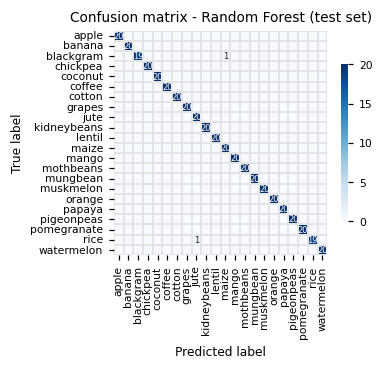

In [17]:
y_pred_test = best_model.predict(X_test)         # first and only use of the test set for scoring

final = {
    "model": best_model_name,
    "accuracy": accuracy_score(y_test, y_pred_test),
    "macro_precision": precision_score(y_test, y_pred_test, average="macro"),
    "macro_recall": recall_score(y_test, y_pred_test, average="macro"),
    "macro_f1": f1_score(y_test, y_pred_test, average="macro"),
    "n_test": len(y_test),
}
pd.Series(final).to_frame("value").to_csv(os.path.join(RES_DIR, "final_test_results.csv"))
for k, v in final.items():
    print(f"{k:16s}: {v:.4f}" if isinstance(v, float) else f"{k:16s}: {v}")

print("\nPer-class report (test set):\n")
print(classification_report(y_test, y_pred_test, zero_division=0))

errors = pd.DataFrame({"true_label": y_test.values, "predicted_label": y_pred_test})
errors = errors[errors.true_label != errors.predicted_label]
print("Misclassified test records:"); display(errors)
errors.to_csv(os.path.join(RES_DIR, "test_misclassifications.csv"), index=False)

plot_cm(confusion_matrix(y_test, y_pred_test, labels=class_labels), class_labels,
        f"Confusion matrix - {best_model_name} (test set)", "fig06_test_confusion_matrix", size=(3.6, 3.4))

## 10. Feature importance (models fitted on training data only)

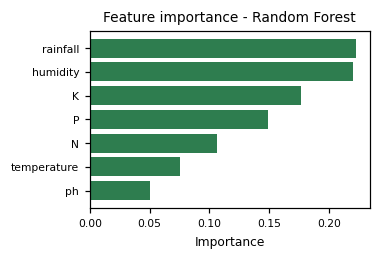

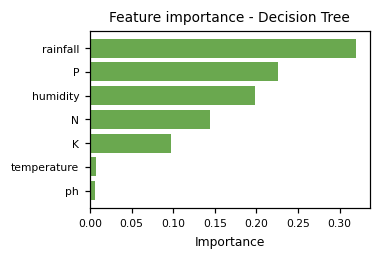

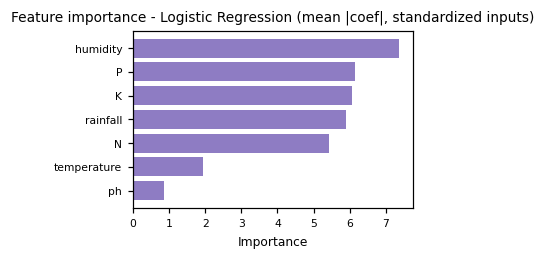

Random Forest ranking: ['rainfall', 'humidity', 'K', 'P', 'N', 'temperature', 'ph']


In [18]:
def plot_importance(name, values, fname, color):
    s = pd.Series(values, index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(3.5, 2.4))
    ax.barh(s.index, s.values, color=color)
    ax.set_xlabel("Importance"); ax.set_title(f"Feature importance - {name}")
    plt.tight_layout(); savefig(fname); plt.show()
    return s.sort_values(ascending=False)

rf_imp = plot_importance("Random Forest", tuned_models["Random Forest"].named_steps["classifier"].feature_importances_, "fig07_feature_importance_random_forest", "#2e7d4f")
dt_imp = plot_importance("Decision Tree", tuned_models["Decision Tree"].named_steps["classifier"].feature_importances_, "figS_feature_importance_decision_tree", "#6aa84f")
coefs = tuned_models["Logistic Regression"].named_steps["classifier"].coef_
lr_imp = plot_importance("Logistic Regression (mean |coef|, standardized inputs)", np.abs(coefs).mean(axis=0), "figS_coefficients_logistic_regression", "#8e7cc3")
pd.DataFrame({"Random Forest": rf_imp, "Decision Tree": dt_imp, "Logistic Regression": lr_imp}).to_csv(os.path.join(RES_DIR, "feature_importance.csv"))
print("Random Forest ranking:", list(rf_imp.index))

## 11. Save the selected model and run metadata

In [19]:
joblib.dump(best_model, "crop_recommendation_model.pkl")
joblib.dump(FEATURES, "feature_names.pkl")
joblib.dump(class_labels, "class_labels.pkl")

metadata = {
    "selected_model": best_model_name,
    "selection_criterion": "highest mean 5-fold CV macro-F1 on the training set",
    "best_hyperparameters": {k: v for k, v in best_params[best_model_name].items()},
    "scikit_learn_version": sklearn.__version__,
    "random_state": RANDOM_STATE,
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "features": FEATURES, "n_classes": len(class_labels),
}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)
print(json.dumps(metadata, indent=2, default=str))

if IN_COLAB:
    from google.colab import files
    for fn in ["crop_recommendation_model.pkl", "feature_names.pkl", "class_labels.pkl", "model_metadata.json"]:
        files.download(fn)

{
  "selected_model": "Random Forest",
  "selection_criterion": "highest mean 5-fold CV macro-F1 on the training set",
  "best_hyperparameters": {
    "max_depth": 16,
    "max_features": "sqrt",
    "min_samples_leaf": 1,
    "min_samples_split": 5,
    "n_estimators": 200
  },
  "scikit_learn_version": "1.9.0",
  "random_state": 42,
  "n_train": 1760,
  "n_test": 440,
  "features": [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
  ],
  "n_classes": 22
}
